# ANÁLISE P4 | _The Numbers Domestic Box Office Dataset_
___
Análises voltadas para responder à pergunta P4.
___

### 0 | Importações
___

In [2]:
# Manipulação de dados:
import pandas as pd
import numpy as np             

# Visualização de dados:
import plotly.express as px 
import plotly.io as pio

pio.renderers.default='png'

In [3]:
df = pd.read_csv('../data/processed/tabela_tratada.csv') # Importando o dataset

### P4 | Explorando dados da evolução da arrecadação dos filmes
___


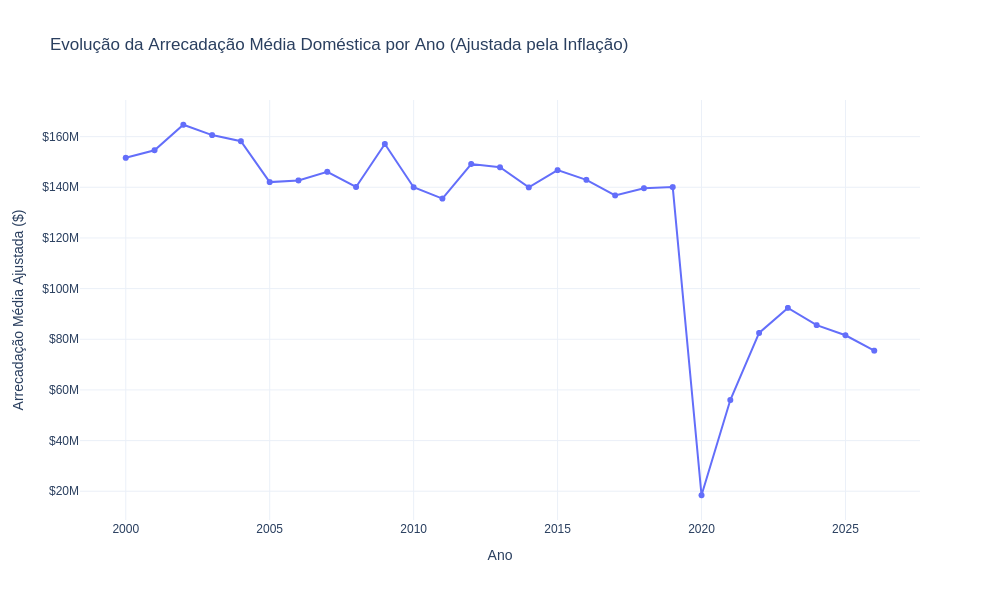

In [4]:
df_anual = df.groupby('year')['domestic_bo'].mean().reset_index()

# Opcional: Se quiser remover eventuais anos nulos ou 0 que possam corromper a linha
#df_anual = df_anual.dropna()

# 3. Cria o gráfico de linhas com Plotly Express
fig = px.line(
    df_anual,
    x='year',                  # Eixo X: Anos
    y='domestic_bo',           # Eixo Y: Arrecadação média
    markers=True,              # Adiciona pontos visíveis em cada ano (facilita o hover)
    title='Evolução da Arrecadação Média Doméstica por Ano (Ajustada pela Inflação)',
    labels={
        'year': 'Ano de Lançamento',
        'domestic_bo': 'Média de Bilheteria Doméstica ($)'
    }
)

# 4. Ajustes visuais para formatar o layout e os eixos
fig.update_layout(
    xaxis_title='Ano',
    yaxis_title='Arrecadação Média Ajustada ($)',
    width=1000,
    height=600,
    template='plotly_white',
    hovermode='x unified'      # Une o tooltip de hover para facilitar a leitura por ano
)

# Formata o eixo Y para exibir os valores de forma amigável (opcional)
fig.update_yaxes(tickprefix='$', separatethousands=True)

# Exibe o gráfico interativo
fig.show()

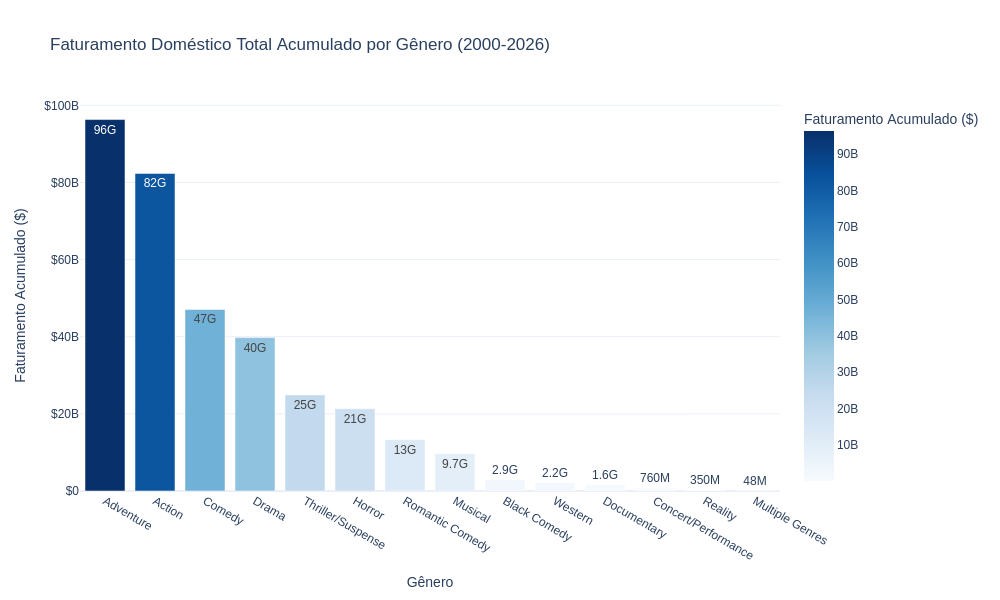

In [5]:
df_fat_total = df.groupby('genre')['domestic_bo'].sum().reset_index(name='faturamento_total')
df_fat_total = df_fat_total.sort_values(by='faturamento_total', ascending=False)

# 3. Cria o gráfico de barras
fig3 = px.bar(
    df_fat_total,
    x='genre',
    y='faturamento_total',
    color='faturamento_total',
    color_continuous_scale='Blues',
    title='Faturamento Doméstico Total Acumulado por Gênero (2000-2026)',
    labels={'genre': 'Gênero', 'faturamento_total': 'Faturamento Acumulado ($)'},
    text_auto='.2s'
)

fig3.update_layout(width=1000, height=600, template='plotly_white', showlegend=False)
fig3.update_yaxes(tickprefix='$', separatethousands=True)
fig3.show()

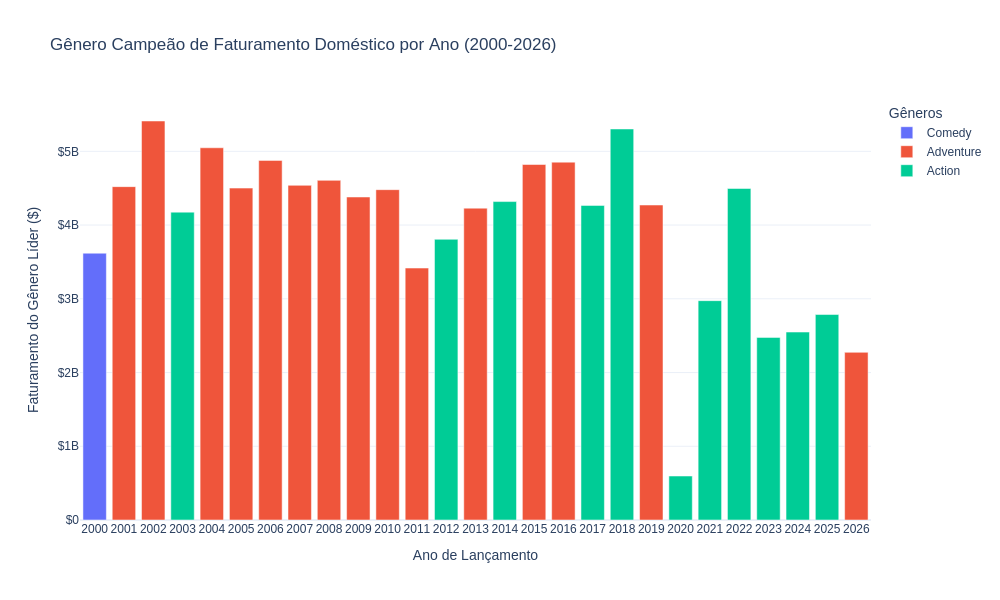

In [6]:
df_fat_ano = df.groupby(['year', 'genre'])['domestic_bo'].sum().reset_index()

# 3. Filtra apenas o gênero com o MAIOR faturamento para cada ano
idx_max = df_fat_ano.groupby('year')['domestic_bo'].idxmax()
df_top_genre = df_fat_ano.loc[idx_max].reset_index(drop=True)

# 4. Ordena estritamente por ano e converte para string (garante a ordem cronológica visual)
df_top_genre = df_top_genre.sort_values('year').reset_index(drop=True)
df_top_genre['year'] = df_top_genre['year'].astype(str)

# 5. Cria o gráfico de barras travando a ordem exata das categorias
fig = px.bar(
    df_top_genre,
    x='year',
    y='domestic_bo',
    color='genre',              # Cada gênero campeão ganha uma cor distinta na legenda
    title='Gênero Campeão de Faturamento Doméstico por Ano (2000-2026)',
    labels={
        'year': 'Ano de Lançamento', 
        'domestic_bo': 'Faturamento do Gênero Líder ($)',
        'genre': 'Gêneros'
    },
    category_orders={'year': df_top_genre['year'].tolist()} # Força a ordem exata da lista
)

# 6. Ajustes visuais
fig.update_layout(
    width=1000, 
    height=600, 
    template='plotly_white'
)
fig.update_yaxes(tickprefix='$', separatethousands=True)

fig.show()

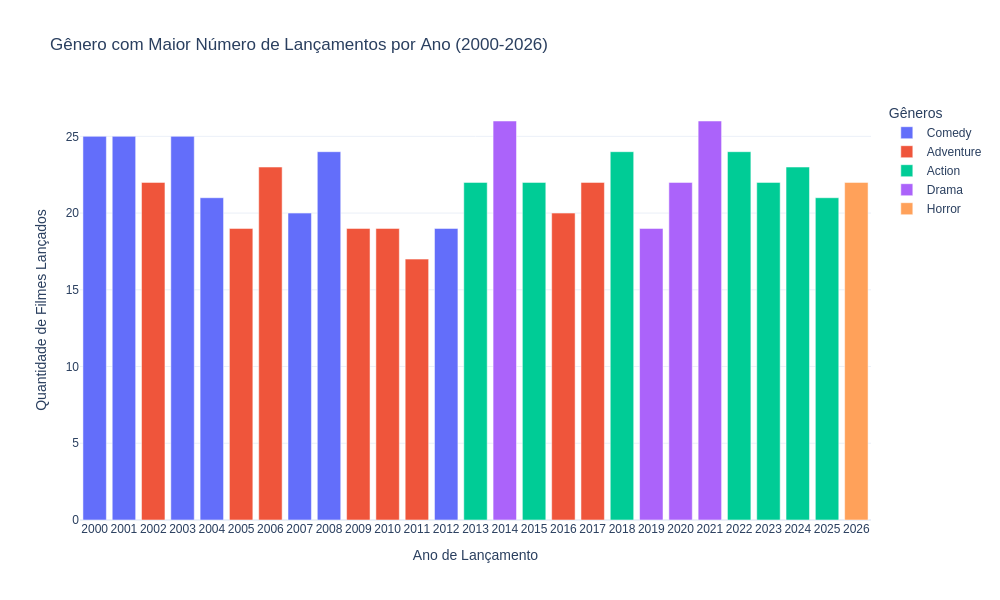

In [7]:
df_qtd_ano = df.groupby(['year', 'genre']).size().reset_index(name='quantidade_filmes')

# 3. Filtra apenas o gênero com o MAIOR número de lançamentos para cada ano
idx_max = df_qtd_ano.groupby('year')['quantidade_filmes'].idxmax()
df_top_lances = df_qtd_ano.loc[idx_max].reset_index(drop=True)

# 4. Ordena estritamente por ano e converte para string (garante a ordem cronológica correta)
df_top_lances = df_top_lances.sort_values('year').reset_index(drop=True)
df_top_lances['year'] = df_top_lances['year'].astype(str)

# 5. Cria o gráfico de barras travando a ordem exata das categorias
fig = px.bar(
    df_top_lances,
    x='year',
    y='quantidade_filmes',
    color='genre',              # Cada gênero campeão ganha uma cor distinta na legenda
    title='Gênero com Maior Número de Lançamentos por Ano (2000-2026)',
    labels={
        'year': 'Ano de Lançamento', 
        'quantidade_filmes': 'Quantidade de Filmes Lançados',
        'genre': 'Gêneros'
    },
    category_orders={'year': df_top_lances['year'].tolist()} # Força a ordem cronológica
)

# 6. Ajustes visuais
fig.update_layout(
    width=1000, 
    height=600, 
    template='plotly_white'
)

fig.show()